In [33]:
#Setup and basic checks
import os
from pathlib import Path
import pandas as pd
import numpy as np

# Paths 
ROOT = Path.cwd()                
IMAGES_DIR = ROOT / "images"     
META_CSV = ROOT / "metadata.csv" 
FEATURES_OUT = ROOT / "features" / "features.csv"

print("Working folder:", ROOT)
print("Images folder:", IMAGES_DIR)
print("Metadata CSV:", META_CSV)
print("Output features path:", FEATURES_OUT)


assert IMAGES_DIR.exists(), f"Images folder not found: {IMAGES_DIR}"
assert META_CSV.exists(), f"Metadata CSV not found: {META_CSV}"

# inspecting metadata
meta = pd.read_csv(META_CSV)
print("Metadata rows:", len(meta))
print(meta.head())


Working folder: c:\Users\Dell\Desktop\MCA\Project Work\SkindiseaseProject
Images folder: c:\Users\Dell\Desktop\MCA\Project Work\SkindiseaseProject\images
Metadata CSV: c:\Users\Dell\Desktop\MCA\Project Work\SkindiseaseProject\metadata.csv
Output features path: c:\Users\Dell\Desktop\MCA\Project Work\SkindiseaseProject\features\features.csv
Metadata rows: 10015
     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear


In [34]:
# Install missing packages 
import sys
import subprocess

def pip_install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])

# Typical required libs
for pkg in ("scikit-image", "scikit-learn", "imblearn", "matplotlib", "scipy"):
    try:
        __import__(pkg.replace('-', '_'))
    except Exception:
        print("Installing", pkg)
        pip_install(pkg)

print("Install step done (or skipped if already present).")


Installing scikit-image
Installing scikit-learn
Install step done (or skipped if already present).


In [35]:
# Feature extraction helper functions 
from skimage.io import imread
from skimage import color
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from scipy.stats import skew
import numpy as np
import math

def color_moments_rgb(img):
    """
    Mean, std, skew for each channel (RGB). Returns 9 numbers.
    """
    if img.ndim == 2:  # grayscale -> broadcast
        img = np.stack([img]*3, axis=-1)
    img = img.astype(np.float32)
    feats = []
    for ch in range(3):
        vals = img[..., ch].ravel()
        feats.append(float(np.mean(vals)))
        feats.append(float(np.std(vals)))
        try:
            feats.append(float(skew(vals)))
        except Exception:
            feats.append(0.0)
    return np.array(feats, dtype=float)

def glcm_features(gray_u8, distances=(1,), angles=(0, np.pi/4, np.pi/2, 3*np.pi/4)):
    """
    Compute 5 GLCM properties averaged over directions:
    contrast, dissimilarity, homogeneity, energy, correlation.
    """
    if gray_u8.dtype != np.uint8:
        norm = (gray_u8 - gray_u8.min()) / (gray_u8.max() - gray_u8.min() + 1e-12)
        gray_u8 = (255 * norm).astype(np.uint8)
    glcm = graycomatrix(gray_u8, distances=distances, angles=angles,
                        symmetric=True, normed=True)
    props = ['contrast','dissimilarity','homogeneity','energy','correlation']
    out = []
    for p in props:
        try:
            v = graycoprops(glcm, p)
            out.append(float(v.mean()))
        except Exception:
            out.append(0.0)
    return np.array(out, dtype=float)

def lbp_histogram(gray, P=8, R=1, method='uniform', n_bins=None):
    """
    Compute LBP (uniform) and return normalized histogram (L1).
    """
    lbp = local_binary_pattern(gray, P, R, method)
    if n_bins is None:
        n_bins = int(lbp.max() + 1)
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
    return hist.astype(float)

def extract_all_features(img_path, lbp_P=8, lbp_R=1, lbp_bins=None):
    """
    Load image, compute ColorMoments (9), GLCM (5), and LBP histogram.
    Returns one feature vector as a numpy array.
    """
    img = imread(str(img_path))

    # discard alpha channel if present
    if img.ndim == 3 and img.shape[2] == 4:
        img = img[..., :3]

    # Color Moments
    cm = color_moments_rgb(img)

    # grayscale for texture features
    gray = color.rgb2gray(img) if img.ndim == 3 else img
    gray_u8 = (255 * gray).astype(np.uint8)

    # GLCM
    gl = glcm_features(gray_u8)

    # LBP
    if lbp_bins is None:
        lbp_bins = lbp_P + 2  # standard for uniform LBP P=8 → 10 bins
    lbp = lbp_histogram(gray, P=lbp_P, R=lbp_R, method='uniform', n_bins=lbp_bins)

    # Combine all features
    return np.concatenate([cm, gl, lbp])


In [36]:
# Test extraction on a single image 
sample_row = meta.iloc[0]   
img_id = sample_row['image_id']
img_path = IMAGES_DIR / f"{img_id}.jpg"

print("Testing on:", img_path)

features = extract_all_features(img_path)

print("Feature vector length:", len(features))
print("First 10 features:", features[:10])


Testing on: c:\Users\Dell\Desktop\MCA\Project Work\SkindiseaseProject\images\ISIC_0027419.jpg
Feature vector length: 24
First 10 features: [208.73623657  12.00697517  -1.13657379 162.70341492  20.24214363
  -0.71059287 181.65930176  29.10260201  -1.00967133  17.4500005 ]


c:\Users\Dell\AppData\Local\Programs\Python\Python310\lib\site-packages\skimage\feature\texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(


In [37]:
# Quick fix: redefine lbp_histogram to use uint8 input for local_binary_pattern
from skimage.util import img_as_ubyte
from skimage.feature import local_binary_pattern
import numpy as np

def lbp_histogram_fixed(gray, P=8, R=1, method='uniform', n_bins=None):
    
    gray_u8 = img_as_ubyte(gray)  
    lbp = local_binary_pattern(gray_u8, P, R, method)
    if n_bins is None:
        n_bins = int(lbp.max() + 1)
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
    return hist.astype(float)


lbp_histogram = lbp_histogram_fixed
print("LBP function updated to use uint8 input (warning silenced).")


LBP function updated to use uint8 input (warning silenced).


In [38]:
# Extract features for many images and save CSV. Use limit for tests
import csv
from tqdm import tqdm  

out_file = FEATURES_OUT
out_file.parent.mkdir(parents=True, exist_ok=True)

limit = None   #extraxts features from entire dataset
rows_written = 0

n_cm = 9
n_glcm = 5
n_lbp = 10  
header = ['image_id', 'dx'] + [f'cm_{i}' for i in range(n_cm)] + \
         [f'glcm_{name}' for name in ('contrast','dissimilarity','homogeneity','energy','correlation')] + \
         [f'lbp_{i}' for i in range(n_lbp)]

with open(out_file, 'w', newline='', encoding='utf8') as fout:
    writer = csv.writer(fout)
    writer.writerow(header)

    total = len(meta) if limit is None else min(limit, len(meta))
    print(f"Extracting features for {total} images (limit={limit}) ...")
    for idx, row in tqdm(meta.iterrows(), total=total):
        if limit is not None and idx >= limit:
            break
        img_id = str(row['image_id']).strip()
        label = str(row['dx']).strip()
        img_file = IMAGES_DIR / f"{img_id}.jpg"
        if not img_file.exists():
        
            if (IMAGES_DIR / f"{img_id}.jpeg").exists():
                img_file = IMAGES_DIR / f"{img_id}.jpeg"
            else:
                print(f"Skipping missing: {img_id}")
                continue

        try:
            feats = extract_all_features(img_file, lbp_P=8, lbp_R=1, lbp_bins=n_lbp)
        except Exception as e:
            print(f"Error on {img_file}: {e}")
            continue

        writer.writerow([img_id, label] + feats.tolist())
        rows_written += 1
        if rows_written % 200 == 0:
            print(f"  processed {rows_written} images...")

print("Done. Rows written:", rows_written)
print("Saved to:", out_file)


Extracting features for 10015 images (limit=None) ...


  0%|          | 0/10015 [00:00<?, ?it/s]

  2%|▏         | 201/10015 [00:27<22:07,  7.39it/s]

  processed 200 images...


  4%|▍         | 401/10015 [00:54<19:52,  8.06it/s]

...

  processed 9800 images...


100%|█████████▉| 10001/10015 [29:57<00:01,  7.35it/s]

  processed 10000 images...


100%|██████████| 10015/10015 [29:58<00:00,  5.57it/s]

Done. Rows written: 10015
Saved to: c:\Users\Dell\Desktop\MCA\Project Work\SkindiseaseProject\features\features.csv


In [39]:

# Load the features file (edit path if you used another name)
feats_df = pd.read_csv(FEATURES_OUT)

print("Features loaded:", feats_df.shape)
print(feats_df.head())

# X = all numeric feature columns
X = feats_df.iloc[:, 2:].values

# y = target labels (disease class)
y = feats_df['dx'].values

print("Feature array shape:", X.shape)
print("Number of labels:", len(y))
print("Unique classes:", sorted(set(y)))


Features loaded: (10015, 26)
       image_id   dx        cm_0       cm_1      cm_2        cm_3       cm_4  \
0  ISIC_0027419  bkl  208.736237  12.006975 -1.136574  162.703415  20.242144   
1  ISIC_0025030  bkl  197.138062  36.200989 -2.342771  156.542435  34.343647   
2  ISIC_0026769  bkl  214.053757  13.762859 -1.619564  156.414948  18.259476   
3  ISIC_0025661  bkl  195.708557  37.920467 -2.149556  142.608032  31.752571   
4  ISIC_0031633  bkl  211.709259  33.448914 -0.923531  167.980270  43.034798   

       cm_5        cm_6       cm_7  ...     lbp_0     lbp_1     lbp_2  \
0 -0.710593  181.659302  29.102602  ...  0.045063  0.063952  0.059619   
1 -1.577866  177.196350  38.629623  ...  0.042052  0.059759  0.061711   
2 -0.185769  174.070984  22.837294  ...  0.036944  0.056574  0.058619   
3 -1.528084  157.175888  36.131947  ...  0.044419  0.063515  0.063126   
4 -0.068589  185.249298  46.784153  ...  0.024063  0.045444  0.040767   

      lbp_3     lbp_4     lbp_5     lbp_6     lbp_7

In [40]:
# All imports 
import time
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             make_scorer, classification_report, confusion_matrix)
import joblib
import seaborn as sns
import matplotlib.pyplot as plt

# Make sure results and models folders exist
Path("results").mkdir(parents=True, exist_ok=True)
Path("models").mkdir(parents=True, exist_ok=True)

print("Imports complete. Ready to train models.")


Imports complete. Ready to train models.


In [41]:
# Train & evaluate SVM, RandomForest, KNN 

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision_macro': make_scorer(precision_score, average='macro', zero_division=0),
    'recall_macro': make_scorer(recall_score, average='macro', zero_division=0),
    'f1_macro': make_scorer(f1_score, average='macro', zero_division=0)
}

models = {
    'SVM_rbf': Pipeline([('scaler', StandardScaler()),
                        ('svm', SVC(kernel='rbf', class_weight='balanced', random_state=42))]),
    'RandomForest': Pipeline([('scaler', StandardScaler()),
                              ('rf', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42))]),
    'KNN': Pipeline([('scaler', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=5))])
}

results_summary = {}

for name, clf in models.items():
    print(f"\n--- Evaluating {name} ---")
    t0 = time.time()
    res = cross_validate(clf, X, y, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)
    elapsed = time.time() - t0
    
    mean_scores = {k: float(v.mean()) for k, v in res.items()}
    mean_scores['time_seconds'] = elapsed
    results_summary[name] = mean_scores

    print(f"Time elapsed: {elapsed:.1f}s")
    print("Accuracy   :", mean_scores.get('test_accuracy'))
    print("Precision  :", mean_scores.get('test_precision_macro'))
    print("Recall     :", mean_scores.get('test_recall_macro'))
    print("F1 (macro) :", mean_scores.get('test_f1_macro'))

    per_model_df = pd.DataFrame([mean_scores])
    per_model_df.to_csv(Path("results") / f"{name}_cv_summary.csv", index=False)
    print(f"Saved results to results/{name}_cv_summary.csv")

    print(f"Training final {name} on full dataset...")
    clf.fit(X, y)
    joblib.dump(clf, Path("models") / f"{name}.joblib")
    print(f"Saved model to models/{name}.joblib")





--- Evaluating SVM_rbf ---
Time elapsed: 20.6s
Accuracy   : 0.6474288567149277
Precision  : 0.43683816001084913
Recall     : 0.5965622635295643
F1 (macro) : 0.47822661686099954
Saved results to results/SVM_rbf_cv_summary.csv
Training final SVM_rbf on full dataset...
Saved model to models/SVM_rbf.joblib

--- Evaluating RandomForest ---
Time elapsed: 11.7s
Accuracy   : 0.7356964553170244
Precision  : 0.6439398139212654
Recall     : 0.335145347258016
F1 (macro) : 0.3863295784578681
Saved results to results/RandomForest_cv_summary.csv
Training final RandomForest on full dataset...
Saved model to models/RandomForest.joblib

--- Evaluating KNN ---
Time elapsed: 0.4s
Accuracy   : 0.7159261108337494
Precision  : 0.5172714200843233
Recall     : 0.39057273907281304
F1 (macro) : 0.4101192425193913
Saved results to results/KNN_cv_summary.csv
Training final KNN on full dataset...
Saved model to models/KNN.joblib



Model comparison saved to results/model_comparison.csv

Summary:
               accuracy  precision_macro  recall_macro  f1_macro  time_seconds
SVM_rbf       0.647429         0.436838      0.596562  0.478227     20.594339
RandomForest  0.735696         0.643940      0.335145  0.386330     11.686933
KNN           0.715926         0.517271      0.390573  0.410119      0.408148

--- Plots for model: SVM_rbf ---
Confusion Matrix (rows=actual, cols=predicted):
[[ 48   8   1   1   5   1   1]
 [ 20  61   7   8   3   2   2]
 [ 18  19 104  12  50  13   4]
 [  4   6   6   6   0   0   1]
 [ 16   4  33   2 150  17   1]
 [ 40  56  79  31 189 930  16]
 [  3   2   1   0   2   1  19]]


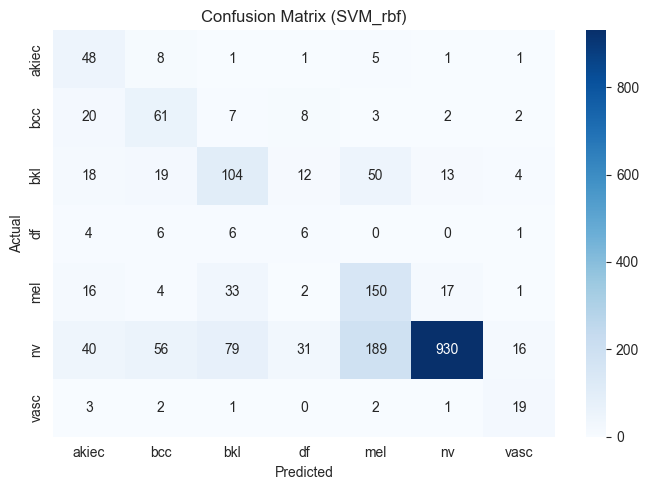

Saved confusion matrix to results\SVM_rbf_confusion_matrix.png


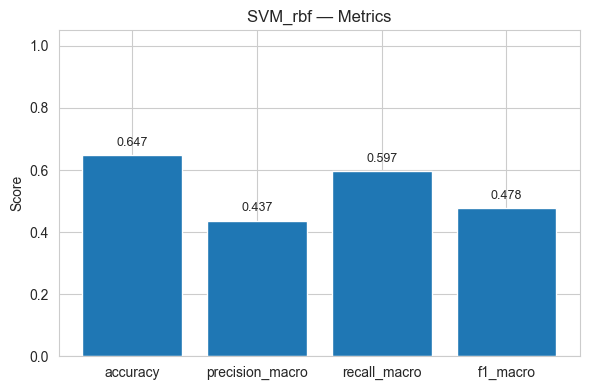

Saved metric bar to results\SVM_rbf_metrics_bar.png

--- Plots for model: RandomForest ---
Confusion Matrix (rows=actual, cols=predicted):
[[  28    7    2    0    2   26    0]
 [   4   26   12    0    3   58    0]
 [   0   11   65    0   18  126    0]
 [   0    0    5    0    0   18    0]
 [   3    1   25    0   56  138    0]
 [   2    4   14    0   11 1310    0]
 [   1    3    2    0    0   18    4]]


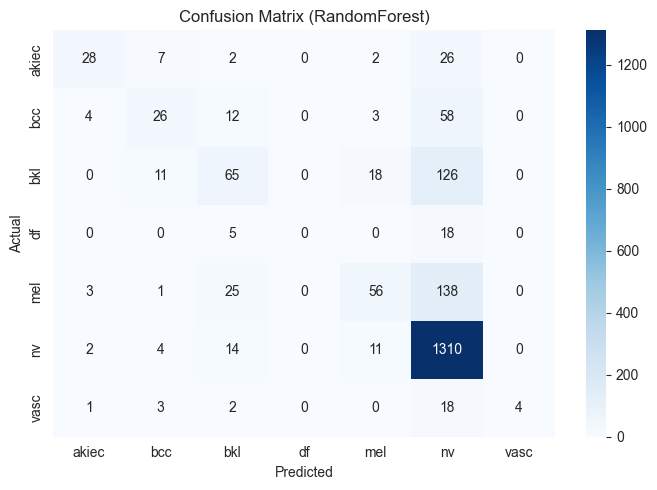

Saved confusion matrix to results\RandomForest_confusion_matrix.png


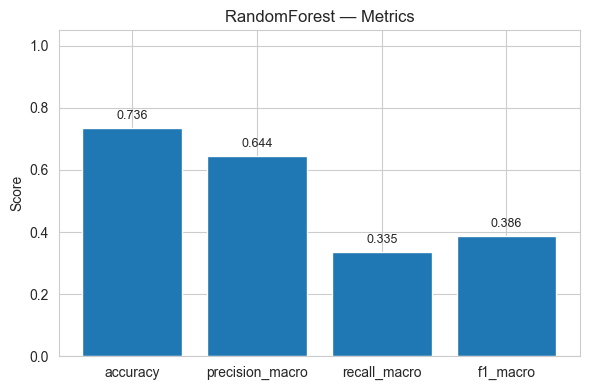

Saved metric bar to results\RandomForest_metrics_bar.png

--- Plots for model: KNN ---
Confusion Matrix (rows=actual, cols=predicted):
[[  28   15    9    0    4    9    0]
 [  17   29   20    0    6   31    0]
 [   8   21   80    1   46   64    0]
 [   2    4    5    1    4    7    0]
 [   8    4   51    1   74   85    0]
 [   9   24   54    1   50 1203    0]
 [   1    3    7    0    3   10    4]]


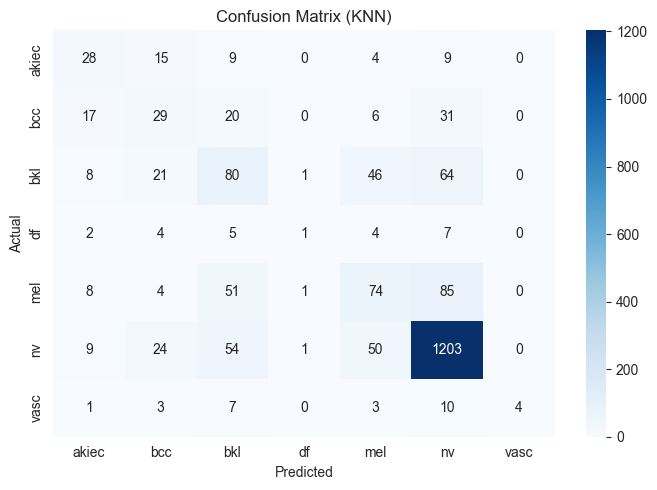

Saved confusion matrix to results\KNN_confusion_matrix.png


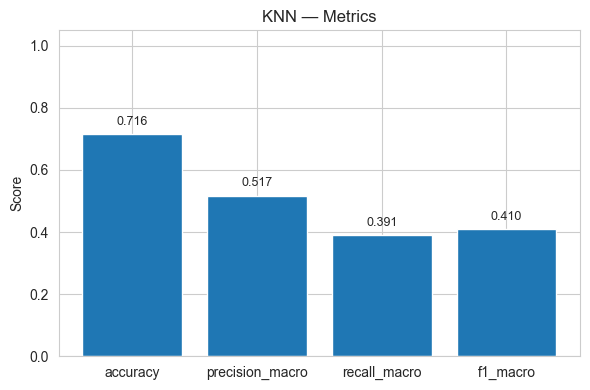

Saved metric bar to results\KNN_metrics_bar.png


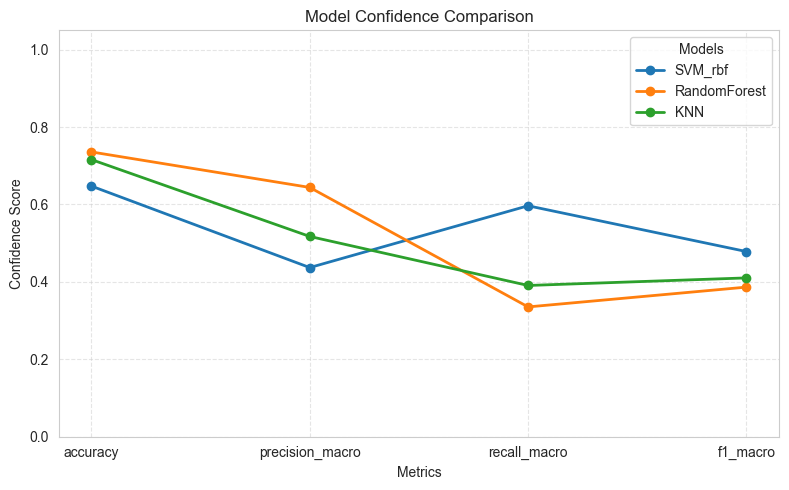


Saved 3-line model confidence graph to results\model_confidence_comparison.png


In [42]:
# --- Replace your old plotting block with this ---

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

results_dir = Path("results")
models_dir = Path("models")
results_dir.mkdir(exist_ok=True)
models_dir.mkdir(exist_ok=True)

# (1) build comp as before
comp = pd.DataFrame(results_summary).T
comp = comp.rename(columns=lambda c: c.replace('test_', ''))  # nicer names
comp = comp[['accuracy','precision_macro','recall_macro','f1_macro','time_seconds']]
comp.to_csv(results_dir / "model_comparison.csv", index=True)
print("\nModel comparison saved to results/model_comparison.csv")
print("\nSummary:\n", comp)

# (2) prepare labels / train-test split once (used for per-model confusion matrices)
le = LabelEncoder()
y_enc = le.fit_transform(y)                  # assumes `y` available in namespace
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=42
)

# list of metrics to display per-model (order matters for bars/line chart)
metric_cols = ['accuracy','precision_macro','recall_macro','f1_macro']

# (3) For each model: plot per-model metric bar + confusion matrix
for model_name in comp.index:
    print(f"\n--- Plots for model: {model_name} ---")
    model_file = models_dir / f"{model_name}.joblib"
    if not model_file.exists():
        # try to find a matching filename if exact not found
        matches = list(models_dir.glob(f"*{model_name}*.joblib"))
        if matches:
            model_file = matches[0]
            print(f"Found model file: {model_file}")
        else:
            print(f"Model file for {model_name} not found in {models_dir}. Skipping this model.")
            continue

    # load model
    clf = joblib.load(model_file)

    # try to fit (keeps your original pattern where you re-fit loaded model)
    try:
        clf.fit(X_train, y_train)
    except Exception as e:
        # Some models may already be fitted or not support fit; proceed to predict
        print(f"Warning: could not fit loaded model {model_name} (this may be okay): {e}")

    # predict and confusion matrix
    try:
        y_pred = clf.predict(X_test)
    except Exception as e:
        print(f"Prediction failed for {model_name}: {e}. Skipping confusion matrix.")
        continue

    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix (rows=actual, cols=predicted):")
    print(cm)

    # --- save & show confusion matrix heatmap ---
    plt.figure(figsize=(7,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.title(f'Confusion Matrix ({model_name})')
    plt.tight_layout()
    cm_path = results_dir / f"{model_name}_confusion_matrix.png"
    plt.savefig(cm_path, dpi=200)
    plt.show()
    plt.close()
    print(f"Saved confusion matrix to {cm_path}")

    # --- per-model metric bar (accuracy, precision, recall, f1) ---
    # make sure the metrics exist in comp; if any missing, use 0 for that metric
    metrics_values = []
    for m in metric_cols:
        val = comp.loc[model_name, m] if m in comp.columns else 0.0
        metrics_values.append(val)

    plt.figure(figsize=(6,4))
    bars = plt.bar(metric_cols, metrics_values)
    plt.ylim(0, 1.05)
    plt.title(f"{model_name} — Metrics")
    plt.ylabel("Score")
    for bar, v in zip(bars, metrics_values):
        plt.text(bar.get_x() + bar.get_width()/2, v + 0.02, f"{v:.3f}", ha='center', va='bottom', fontsize=9)
    plt.tight_layout()
    met_path = results_dir / f"{model_name}_metrics_bar.png"
    plt.savefig(met_path, dpi=200)
    plt.show()
    plt.close()
    print(f"Saved metric bar to {met_path}")

# --- 3-line Model Confidence Chart (SVM, RF, KNN) ---
metrics = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

plt.figure(figsize=(8,5))

for model_name in comp.index:
    plt.plot(metrics,
             comp.loc[model_name, metrics].values,
             marker='o',
             linewidth=2,
             label=model_name)

plt.title("Model Confidence Comparison")
plt.xlabel("Metrics")
plt.ylabel("Confidence Score")
plt.ylim(0, 1.05)
plt.grid(linestyle='--', alpha=0.5)
plt.legend(title="Models")
plt.tight_layout()

conf_path = results_dir / "model_confidence_comparison.png"
plt.savefig(conf_path, dpi=200)
plt.show()
plt.close()

print(f"\nSaved 3-line model confidence graph to {conf_path}")

